In [52]:
from IPython.display import Image, display

image_url = "https://images.openai.com/static-rsc-4/DwldS-9UpnF3z1Dz1WtHAP4BIM9L62bdQmltpYWOWNZkU2HyNVaBKYaq2hFmvEwPtIhhOVZO22ljgk_88FHng-Pu89LHy8kwkLNBbH1u_3Ll-XyczeshB3VEuj9eN25Iaw-PgmgJhl-5JJ3BSUagx5dMzMLx57dF0aqiH6PEIdNLGFRZ0jKxZajT6KmjmWDi?purpose=fullsize"

display(Image(url=image_url))

# Traffic Sign Image Classification Using Machine Learning

## Project Objective
The objective of this project is to classify traffic sign images
using Machine Learning algorithms such as KNN and Decision Tree.

In [6]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [31]:
DATASET_PATH = r"C:\Users\LENOVO\OneDrive\Documents\Python 548A\NLP Project\Traffic_Sign_Classification\GTSRB_Final_Training_Images\GTSRB\Final_Training\Images"

print("Dataset exists:", os.path.exists(DATASET_PATH))

Dataset exists: True


In [32]:
folders = sorted(os.listdir(DATASET_PATH))

print("Total class folders:", len(folders))
print("First 15 folders:", folders[:15])

Total class folders: 43
First 15 folders: ['00000', '00001', '00002', '00003', '00004', '00005', '00006', '00007', '00008', '00009', '00010', '00011', '00012', '00013', '00014']


In [33]:
selected_classes = [1, 2, 14, 17, 27]

for class_id in selected_classes:
    folder_name = format(class_id, "05d")
    folder_path = os.path.join(DATASET_PATH, folder_name)

    print(folder_name, ":", len(os.listdir(folder_path)), "images")

00001 : 2221 images
00002 : 2251 images
00014 : 781 images
00017 : 1111 images
00027 : 241 images


In [34]:
X = []
y = []

for class_id in selected_classes:

    folder_name = format(class_id, "05d")
    folder_path = os.path.join(DATASET_PATH, folder_name)

    image_files = sorted(os.listdir(folder_path))

    # Select maximum 200 images
    image_files = image_files[:200]

    for image_name in image_files:

        image_path = os.path.join(folder_path, image_name)

        image = cv2.imread(image_path)

        if image is not None:

            # Resize image
            image = cv2.resize(image, (32, 32))

            # Convert into grayscale
            image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

            X.append(image)
            y.append(class_id)

X = np.array(X)
y = np.array(y)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Total images:", len(X))

Images shape: (1000, 32, 32)
Labels shape: (1000,)
Total images: 1000


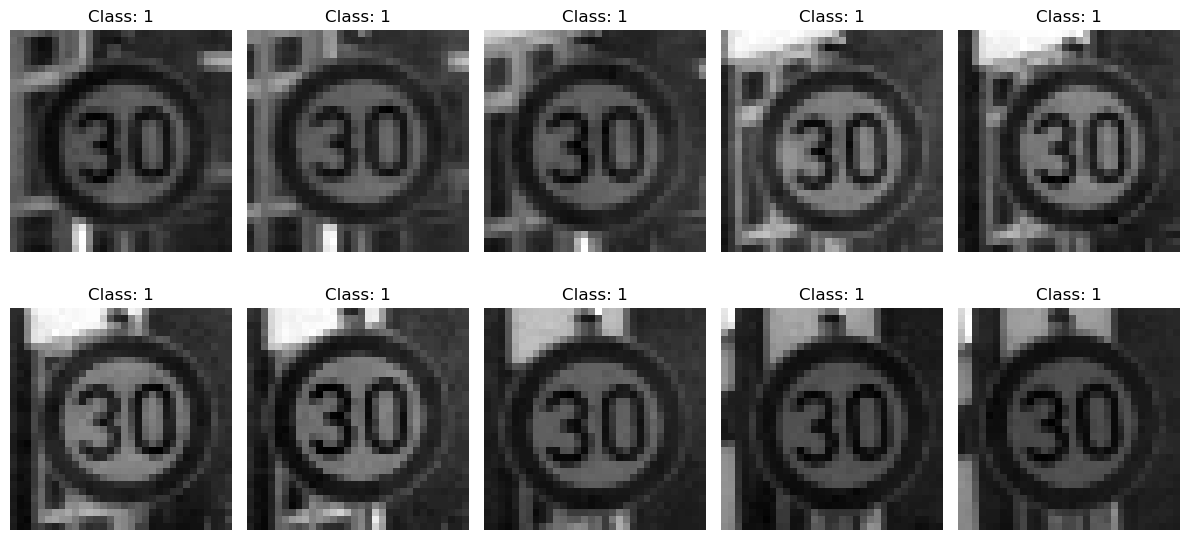

In [35]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i], cmap="gray")
    plt.title("Class: " + str(y[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [36]:
# Prepare the data and train models

# Normalize pixel values
X = X / 255.0

# Flatten images into one-dimensional arrays
X = X.reshape(X.shape[0], -1)

print("Final X shape:", X.shape)
print("Final y shape:", y.shape)

Final X shape: (1000, 1024)
Final y shape: (1000,)


# Simple explanation:
- Normalization converts pixel values into a range between 0 and 1.
- Flattening converts each 32 × 32 image into a single row containing 1,024 values.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])

Training images: 800
Testing images: 200


In [38]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

knn_predictions = knn_model.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:", knn_accuracy)
print("KNN Accuracy Percentage:", knn_accuracy * 100)

KNN Accuracy: 0.94
KNN Accuracy Percentage: 94.0


In [39]:
dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_predictions)

print("Decision Tree Accuracy:", dt_accuracy)
print("Decision Tree Accuracy Percentage:", dt_accuracy * 100)

Decision Tree Accuracy: 0.89
Decision Tree Accuracy Percentage: 89.0


In [40]:
results = pd.DataFrame({
    "Model": ["KNN", "Decision Tree"],
    "Accuracy": [knn_accuracy, dt_accuracy]
})

results["Accuracy Percentage"] = results["Accuracy"] * 100

print(results)

           Model  Accuracy  Accuracy Percentage
0            KNN      0.94                 94.0
1  Decision Tree      0.89                 89.0


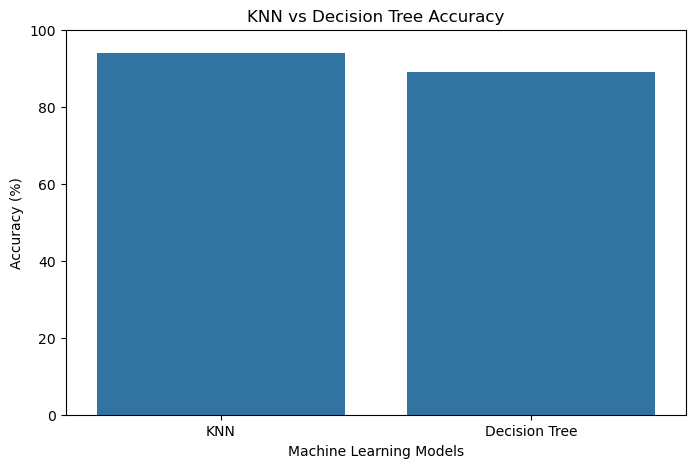

In [41]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy Percentage"
)

plt.title("KNN vs Decision Tree Accuracy")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 100)

plt.show()

In [42]:
print("KNN Classification Report")

print(classification_report(
    y_test,
    knn_predictions,
    labels=selected_classes,
    zero_division=0
))

KNN Classification Report
              precision    recall  f1-score   support

           1       0.97      0.88      0.92        40
           2       0.82      1.00      0.90        40
          14       1.00      0.95      0.97        40
          17       0.95      0.97      0.96        40
          27       1.00      0.90      0.95        40

    accuracy                           0.94       200
   macro avg       0.95      0.94      0.94       200
weighted avg       0.95      0.94      0.94       200



In [43]:
print("Decision Tree Classification Report")

print(classification_report(
    y_test,
    dt_predictions,
    labels=selected_classes,
    zero_division=0
))

Decision Tree Classification Report
              precision    recall  f1-score   support

           1       0.81      0.88      0.84        40
           2       0.86      0.75      0.80        40
          14       0.92      0.88      0.90        40
          17       0.91      1.00      0.95        40
          27       0.95      0.95      0.95        40

    accuracy                           0.89       200
   macro avg       0.89      0.89      0.89       200
weighted avg       0.89      0.89      0.89       200



The report displays:
- Precision: How many of the model's predictions for a class were correct.
- Recall: How many actual images of a class the model identified correctly.
- F1-score: A combined measure of precision and recall.
- Support: Number of actual test images in each class.

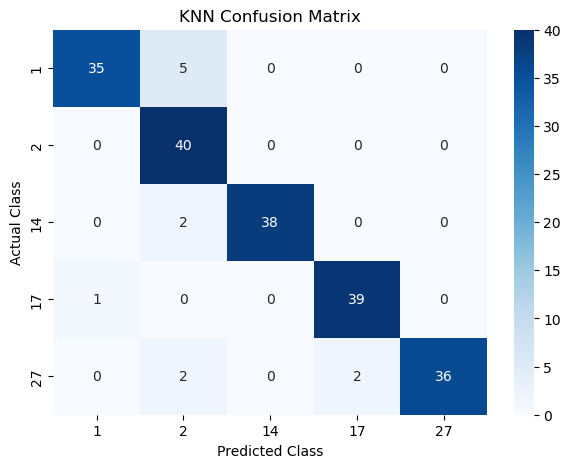

In [44]:
cm_knn = confusion_matrix(
    y_test,
    knn_predictions,
    labels=selected_classes
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=selected_classes,
    yticklabels=selected_classes
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

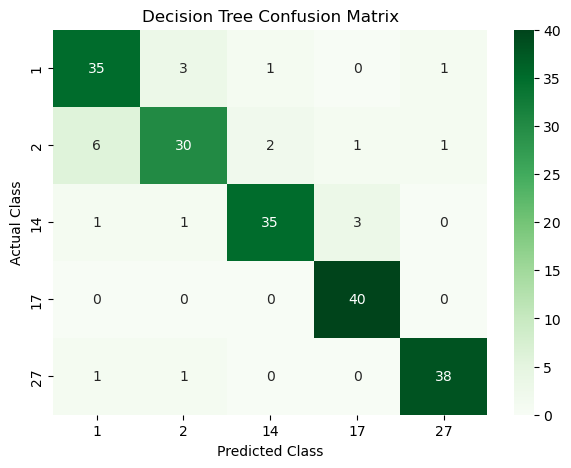

In [45]:
cm_dt = confusion_matrix(
    y_test,
    dt_predictions,
    labels=selected_classes
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=selected_classes,
    yticklabels=selected_classes
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [50]:
# Predict a new traffic sign image

new_image_path = r"C:\Users\LENOVO\OneDrive\Documents\Python 548A\NLP Project\Traffic_Sign_Classification\new_traffic_sign.webp"

new_image = cv2.imread(new_image_path)

if new_image is None:
    print("Image not found. Please check the image path.")

else:
    # Resize image
    new_image = cv2.resize(new_image, (32, 32))

    # Convert to grayscale
    new_image = cv2.cvtColor(new_image, cv2.COLOR_BGR2GRAY)

    # Normalize
    new_image = new_image / 255.0

    # Flatten
    new_image = new_image.reshape(1, -1)

    # Predict using both models
    knn_prediction = knn_model.predict(new_image)
    dt_prediction = dt_model.predict(new_image)

    class_names = {
        1: "Speed Limit 30",
        2: "Speed Limit 50",
        14: "Stop",
        17: "No Entry",
        27: "Pedestrians"
    }

    print("KNN Prediction:", class_names[knn_prediction[0]])
    print("Decision Tree Prediction:", class_names[dt_prediction[0]])

KNN Prediction: Stop
Decision Tree Prediction: Pedestrians


## Conclusion

In this project, I implemented a Traffic Sign Image Classification system using Machine Learning.

I used the GTSRB traffic sign dataset and selected five different traffic sign classes for classification.

I performed image preprocessing by resizing images, converting them into grayscale, normalizing pixel values, and flattening them.

I trained two machine learning algorithms: K-Nearest Neighbors (KNN) and Decision Tree.

I evaluated both models using accuracy, classification reports, and confusion matrices. I also tested the trained models using a new traffic sign image.

Through this project, I gained practical knowledge of image preprocessing, machine learning model training, evaluation, and image classification.